# 🍷 Are More Expensive Wines Actually Rated Higher?

## Project Objective

This project investigates the relationship between wine prices and professional ratings. The goal is to determine whether more expensive wines tend to receive higher ratings and whether machine learning can help predict a wine's rating.

## Research Questions

- Is there a relationship between wine price and rating?
- Do higher-priced wines receive higher ratings on average?
- Can we predict a wine's rating using its price and other available features?

## Dataset

The project uses the Wine Enthusiast wine reviews dataset, which contains information about wine prices, professional ratings, countries of origin, varieties, wineries, and descriptions.


## Machine Learning Objective

The original research question is: *Are more expensive wines actually rated higher?*

To address the Machine Learning requirements, this project uses supervised regression to predict professional wine ratings (`points`) based on three features: `price`, `variety`, and `country`.

We compare Linear Regression and Random Forest models to evaluate how accurately wine ratings can be predicted and which features provide the strongest predictive information.

Exploratory Data Analysis investigates the relationship between price and ratings, while the Machine Learning models investigate the predictive value of price and other wine characteristics.

Professional ratings serve as a proxy for perceived wine quality rather than an objective measure of quality. The models identify predictive relationships, not causal effects.

In [1]:
from sklearn.datasets import load_iris, fetch_california_housing
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV

In [2]:
# Load the Wine Enthusiast dataset
df = pd.read_csv("wine-price.csv")

## Initial Data Exploration

The first step is to understand the dataset's structure, including its dimensions, columns, data types, and the first few observations.


In [3]:
df.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [4]:
df.shape

(129971, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129971 entries, 0 to 129970
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             129971 non-null  int64  
 1   country                129908 non-null  str    
 2   description            129971 non-null  str    
 3   designation            92506 non-null   str    
 4   points                 129971 non-null  int64  
 5   price                  120975 non-null  float64
 6   province               129908 non-null  str    
 7   region_1               108724 non-null  str    
 8   region_2               50511 non-null   str    
 9   taster_name            103727 non-null  str    
 10  taster_twitter_handle  98758 non-null   str    
 11  title                  129971 non-null  str    
 12  variety                129970 non-null  str    
 13  winery                 129971 non-null  str    
dtypes: float64(1), int64(2), str(11)
memory usage: 

In [6]:
df.isnull().sum()

Unnamed: 0                   0
country                     63
description                  0
designation              37465
points                       0
price                     8996
province                    63
region_1                 21247
region_2                 79460
taster_name              26244
taster_twitter_handle    31213
title                        0
variety                      1
winery                       0
dtype: int64

### Data Quality Assessment

We will investigate missing values and identify columns that may not be useful for the analysis.

Missing values are particularly important in the `price` column because the main research question investigates the relationship between wine prices and ratings.


In [9]:
# Calculate the number and percentage of missing values in each column
missing_summary = pd.DataFrame(
    {
        "Missing Values": df.isnull().sum(),
        "Missing Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

# Display columns with missing values, sorted from highest to lowest
missing_summary[missing_summary["Missing Values"] > 0].sort_values(
    by="Missing Percentage (%)", ascending=False
)

,Missing Values,Missing Percentage (%)
region_2,79460,61.14
designation,37465,28.83
taster_twitter_handle,31213,24.02
taster_name,26244,20.19
region_1,21247,16.35
price,8996,6.92
country,63,0.05
province,63,0.05
variety,1,0.00


In [10]:
# Inspect the first and last values of the saved index column
df["Unnamed: 0"].head(), df["Unnamed: 0"].tail()

(0    0
 1    1
 2    2
 3    3
 4    4
 Name: Unnamed: 0, dtype: int64,
 129966    129966
 129967    129967
 129968    129968
 129969    129969
 129970    129970
 Name: Unnamed: 0, dtype: int64)

### Identifying Relevant Features

The dataset contains information about wine prices, professional ratings, wine varieties, countries, regions, and reviewers.

- **Target variable:** `points` — the professional rating we want to understand and potentially predict.
- **Main explanatory variable:** `price` — the wine's price.
- **Additional features:** `variety`, `country`, and other wine characteristics that may help explain ratings.

In [11]:
# Explore the distribution of wine ratings and prices
df[["points", "price"]].describe()

,points,price
count,129971.000000,120975.000000
mean,88.447138,35.363389
std,3.039730,41.022218
min,80.000000,4.000000
25%,86.000000,17.000000
50%,88.000000,25.000000
75%,91.000000,42.000000
max,100.000000,3300.000000


In [12]:
# Check how many distinct ratings and prices exist
df[["points", "price"]].nunique()

points     21
price     390
dtype: int64

### Exploring the Distributions of Price and Ratings

Before investigating the relationship between wine price and professional ratings, we will examine the distribution of each variable.


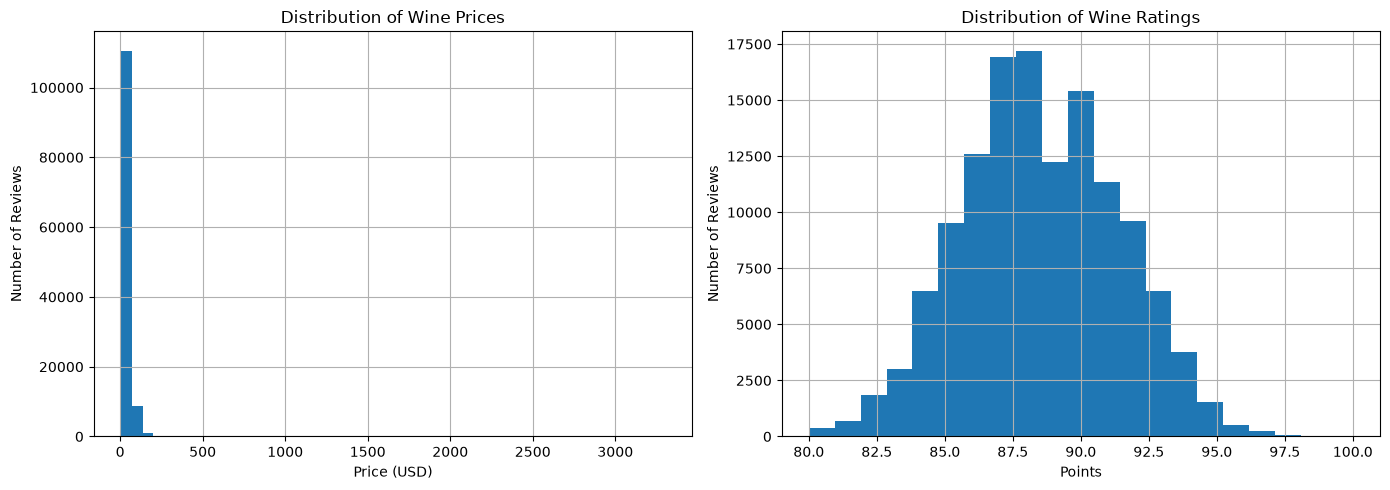

In [14]:
# Create histograms for wine price and professional ratings
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of wine prices
df["price"].dropna().hist(bins=50, ax=axes[0])
axes[0].set_title("Distribution of Wine Prices")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Number of Reviews")

# Distribution of wine ratings
df["points"].hist(bins=21, ax=axes[1])
axes[1].set_title("Distribution of Wine Ratings")
axes[1].set_xlabel("Points")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

### Exploring the Relationship Between Price and Rating

We will use a scatter plot to investigate whether wine prices are associated with professional ratings.

Because a small number of wines have very high prices, the initial visualization will focus on wines priced at $200 or less.


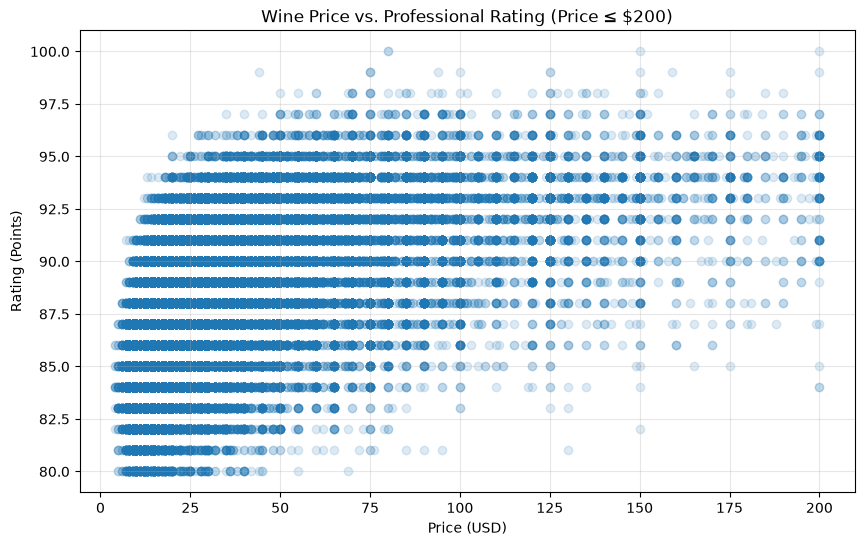

In [15]:
# Select wines with available prices up to $200 for visualization
df_price_plot = df[df["price"].notna() & (df["price"] <= 200)]

# Plot price against professional rating
plt.figure(figsize=(10, 6))
plt.scatter(df_price_plot["price"], df_price_plot["points"], alpha=0.15)

plt.title("Wine Price vs. Professional Rating (Price ≤ $200)")
plt.xlabel("Price (USD)")
plt.ylabel("Rating (Points)")
plt.grid(True, alpha=0.3)
plt.show()

### Correlation Between Wine Price and Rating

To quantify the relationship between price and professional rating, we will calculate the Pearson correlation coefficient.

In [16]:
# Select rows with available prices and ratings
df_price_rating = df[["price", "points"]].dropna()

# Calculate the Pearson correlation coefficient
correlation = df_price_rating["price"].corr(df_price_rating["points"])

# Display the result
print(f"Correlation between price and rating: {correlation:.4f}")

Correlation between price and rating: 0.4162


There is a moderate positive relationship between wine price and professional rating. More expensive wines tend to receive higher scores, but the relationship is not particularly strong.

### Comparing Ratings Across Price Categories

To make the relationship between price and rating easier to interpret, we will group wines into price categories and calculate the average rating for each category.

This analysis will help us determine whether average professional ratings increase as wine prices rise.


In [17]:
# Create price categories for wines with known prices
df_price_groups = df[df["price"].notna()].copy()

df_price_groups["price_category"] = pd.cut(
    df_price_groups["price"],
    bins=[0, 15, 30, 50, 100, float("inf")],
    labels=["$0–15", "$15–30", "$30–50", "$50–100", "$100+"],
    include_lowest=True,
)

# Calculate the number of reviews and average rating in each category
price_rating_summary = (
    df_price_groups.groupby("price_category", observed=False)
    .agg(
        number_of_reviews=("points", "count"),
        average_rating=("points", "mean"),
        median_rating=("points", "median"),
    )
    .round(2)
)

price_rating_summary

,number_of_reviews,average_rating,median_rating
price_category,,,
$0–15,25102,85.91,86.0
$15–30,48353,87.86,88.0
$30–50,27746,89.59,90.0
$50–100,16408,91.05,91.0
$100+,3366,92.82,93.0


Average professional rating increases across the five price categories in the dataset.

## Data Cleaning and Preparation

Before building machine learning models, we need to prepare the dataset.

- Remove the saved index column, which is not a meaningful predictive feature.
- Keep observations with known prices, since price is our main explanatory variable.
- Check for duplicate observations.
- Select the relevant features and target variable for our regression models.


In [18]:
# Create a working copy and remove the saved index column
df_clean = df.drop(columns=["Unnamed: 0"]).copy()

# Keep only rows with a known price for the price-rating analysis
df_clean = df_clean.dropna(subset=["price"])

# Check the resulting dataset dimensions
print("Dataset shape after removing missing prices:", df_clean.shape)

# Check for duplicate rows
print("Number of duplicate rows:", df_clean.duplicated().sum())

Dataset shape after removing missing prices: (120975, 13)
Number of duplicate rows: 9382


In [19]:
# Display exact duplicate rows for inspection
duplicate_rows = df_clean[df_clean.duplicated(keep=False)]

duplicate_rows.head(10)

,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
9,France,This has great depth of flavor with its fresh ...,Les Natures,87,27.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,Pinot Gris,Jean-Baptiste Adam
10,US,"Soft, supple plum envelopes an oaky structure ...",Mountain Cuvée,87,19.0,California,Napa Valley,Napa,Virginie Boone,@vboone,Kirkland Signature 2011 Mountain Cuvée Caberne...,Cabernet Sauvignon,Kirkland Signature
11,France,"This is a dry wine, very spicy, with a tight, ...",NaN,87,30.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Leon Beyer 2012 Gewurztraminer (Alsace),Gewürztraminer,Leon Beyer
12,US,"Slightly reduced, this wine offers a chalky, t...",NaN,87,34.0,California,Alexander Valley,Sonoma,Virginie Boone,@vboone,Louis M. Martini 2012 Cabernet Sauvignon (Alex...,Cabernet Sauvignon,Louis M. Martini
14,US,Building on 150 years and six generations of w...,NaN,87,12.0,California,Central Coast,Central Coast,Matt Kettmann,@mattkettmann,Mirassou 2012 Chardonnay (Central Coast),Chardonnay,Mirassou
16,Argentina,"Baked plum, molasses, balsamic vinegar and che...",Felix,87,30.0,Other,Cafayate,NaN,Michael Schachner,@wineschach,Felix Lavaque 2010 Felix Malbec (Cafayate),Malbec,Felix Lavaque
17,Argentina,Raw black-cherry aromas are direct and simple ...,Winemaker Selection,87,13.0,Mendoza Province,Mendoza,NaN,Michael Schachner,@wineschach,Gaucho Andino 2011 Winemaker Selection Malbec ...,Malbec,Gaucho Andino
23,US,This wine from the Geneseo district offers aro...,Signature Selection,87,22.0,California,Paso Robles,Central Coast,Matt Kettmann,@mattkettmann,Bianchi 2011 Signature Selection Merlot (Paso ...,Merlot,Bianchi
41,US,"A stiff, tannic wine, this slowly opens and br...",NaN,86,22.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Hawkins Cellars 2009 Pinot Noir (Willamette Va...,Pinot Noir,Hawkins Cellars
42,France,"This is a festive wine, with soft, ripe fruit ...",Nouveau,86,9.0,Beaujolais,Beaujolais,NaN,Roger Voss,@vossroger,Henry Fessy 2012 Nouveau (Beaujolais),Gamay,Henry Fessy


In [20]:
# Compare the dataset size before and after removing exact duplicates
print("Before:", df_clean.shape)
print("After:", df_clean.drop_duplicates().shape)

Before: (120975, 13)
After: (111593, 13)


### Removing Exact Duplicates

The dataset contains 9'382 exact duplicate rows after excluding observations with missing prices.

In [21]:
# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Check the dataset dimensions after cleaning
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Dataset shape after removing duplicates: (111593, 13)
Remaining duplicate rows: 0


## Preparing Features and Target

For the first regression model:
- **X (features):** Wine price.
- **y (target):** Professional rating in points.


In [29]:
# Select the feature and target variables
X = df_clean[["price"]]
y = df_clean["points"]

# Inspect the first few observations
X.head(), y.head()

(   price
 1   15.0
 2   14.0
 3   13.0
 4   65.0
 5   15.0,
 1    87
 2    87
 3    87
 4    87
 5    87
 Name: points, dtype: int64)

### Train-Test Split


In [30]:
# Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=17
)

### Model 1: Linear Regression

Wine price will be the input feature (`X`) to predict the professional rating (`y`).

In [34]:
# Initialize the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['price']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,87.35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [35]:
# Display the model's intercept and price coefficient
print("Intercept:", lr_model.intercept_)
print("Price coefficient:", lr_model.coef_[0])

Intercept: 87.35048181204526
Price coefficient: 0.02985333236771995


In [36]:
# Predict ratings using the trained Linear Regression model
y_pred = lr_model.predict(X_test)

# Compare actual ratings with predicted ratings
comparison = pd.DataFrame({"Actual Rating": y_test, "Predicted Rating": y_pred})

# Display the first 10 predictions
comparison.head(10)

,Actual Rating,Predicted Rating
30513,90,87.619162
27121,87,87.768428
85470,92,88.813295
61422,82,87.678868
60961,93,89.738748
7007,89,88.753588
81510,87,88.096815
62466,87,87.887842
69140,88,87.857988
38077,89,89.440215


## Model Evaluation

We will evaluate the Linear Regression model on the test set using three metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted ratings.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger errors more heavily.
- **R2 Score:** Measures how much of the variation in ratings is explained by the model.

These metrics will help us determine whether wine price alone is sufficient to predict professional ratings.


In [40]:
# Calculate evaluation metrics on the test set
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

# Display the results
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

MAE: 2.239
RMSE: 2.783
R2 Score: 0.191


Linear Regression model explains only 19.1% of the variation in ratings using price alone. Price therefore has limited predictive power on its own.

### Findings

More expensive wines tend to receive higher professional ratings on average, but price alone is not a reliable indicator of a wine's rating.

### Model 1: Improving the Model with Additional Features

The baseline model uses only price to predict wine ratings. Its R2 score indicates that price alone explains a limited proportion of the variation in ratings.

We will now investigate whether including wine variety and country improves predictive performance.

In [41]:
# Inspect the number of unique categories in each feature
print("Unique wine varieties:", df_clean["variety"].nunique())
print("Unique countries:", df_clean["country"].nunique())

# Check missing values in the proposed features
print("\nMissing values:")
print(df_clean[["price", "variety", "country", "points"]].isnull().sum())

# Inspect the most frequent categories
print("\nTop 10 wine varieties:")
print(df_clean["variety"].value_counts().head(10))

print("\nTop 10 countries:")
print(df_clean["country"].value_counts().head(10))

Unique wine varieties: 697
Unique countries: 42

Missing values:
price       0
variety     1
country    55
points      0
dtype: int64

Top 10 wine varieties:
variety
Pinot Noir                  11835
Chardonnay                  10238
Cabernet Sauvignon           8763
Red Blend                    7809
Bordeaux-style Red Blend     4958
Riesling                     4572
Sauvignon Blanc              4403
Syrah                        3778
Rosé                         2951
Merlot                       2856
Name: count, dtype: int64

Top 10 countries:
country
US           50238
France       16286
Italy        15506
Spain         6049
Portugal      4502
Chile         4130
Argentina     3501
Austria       2536
Australia     2169
Germany       1951
Name: count, dtype: int64


### Model 2: Linear Regression with Additional Features

The baseline model uses only price to predict wine ratings. In this model, we will add wine variety and country to investigate whether these characteristics improve predictive performance.

We will use one-hot encoding to convert categorical features into numerical variables.

All preprocessing will be fitted using the training data only to prevent data leakage.


In [42]:
# Define the features and target for Model 2
X_multi = df_clean[["price", "variety", "country"]]
y_multi = df_clean["points"]

# Split the data, using the same random state as Model 1
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=17
)

print("Training set:", X_train_multi.shape)
print("Test set:", X_test_multi.shape)

Training set: (89274, 3)
Test set: (22319, 3)


In [44]:
# Define numerical and categorical preprocessing
numeric_features = ["price"]
categorical_features = ["variety", "country"]

numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median"))])

categorical_transformer = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer(
    [
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# Combine preprocessing with Linear Regression
model_multi = Pipeline(
    [("preprocessor", preprocessor), ("regressor", LinearRegression())]
)

# Train the model
model_multi.fit(X_train_multi, y_train_multi)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['price','variety','country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the t

In [46]:
# Predict ratings on the test set
y_pred_multi = model_multi.predict(X_test_multi)

# Calculate regression metrics
mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
rmse_multi = mean_squared_error(y_test_multi, y_pred_multi) ** 0.5
r2_multi = r2_score(y_test_multi, y_pred_multi)

print(f"MAE: {mae_multi:.3f}")
print(f"RMSE: {rmse_multi:.3f}")
print(f"R2 Score: {r2_multi:.3f}")

MAE: 2.138
RMSE: 2.664
R2 Score: 0.258


#### Visualizing Model Predictions


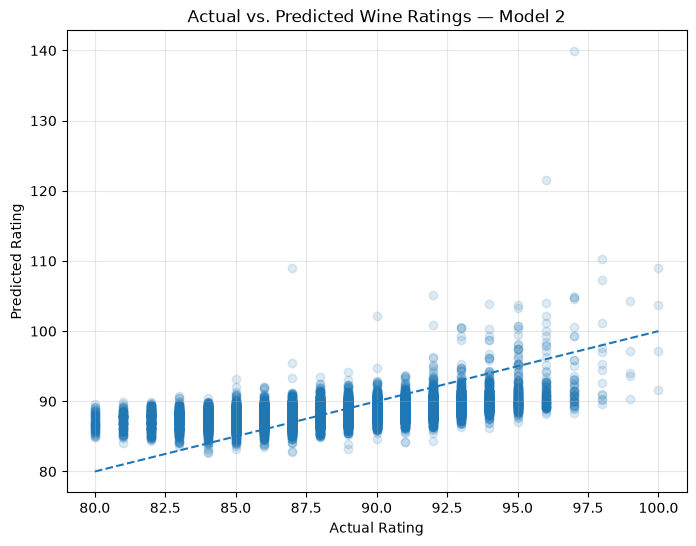

In [47]:
# Plot actual ratings against predicted ratings
plt.figure(figsize=(8, 6))

plt.scatter(y_test_multi, y_pred_multi, alpha=0.15)

# Add a reference line representing perfect predictions
plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    linestyle="--",
)

plt.title("Actual vs. Predicted Wine Ratings — Model 2")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.grid(True, alpha=0.3)
plt.show()

In [48]:
# Inspect the range of predicted ratings from Model 2
print("Minimum predicted rating:", y_pred_multi.min())
print("Maximum predicted rating:", y_pred_multi.max())

# Display the predictions with the highest values
print("\nHighest predicted ratings:")
print(
    pd.DataFrame({"Actual Rating": y_test_multi, "Predicted Rating": y_pred_multi})
    .sort_values("Predicted Rating", ascending=False)
    .head(10)
)

Minimum predicted rating: 82.66192702581174
Maximum predicted rating: 139.85196969477755

Highest predicted ratings:
        Actual Rating  Predicted Rating
65352              97        139.851970
1575               96        121.589573
77028              98        110.223024
122935            100        109.052167
78235              87        108.975187
82751              98        107.313306
96148              92        105.173996
108645             97        104.892525
117029             97        104.830048
121934             97        104.521768


In [49]:

# Find the test observation with the highest predicted rating
highest_prediction_index = y_pred_multi.argmax()

# Inspect the features used for this prediction
print("Wine features:")
print(X_test_multi.iloc[highest_prediction_index])

# Compare the actual and predicted ratings
print("\nActual rating:", y_test_multi.iloc[highest_prediction_index])
print("Predicted rating:", y_pred_multi[highest_prediction_index])


Wine features:
price                        2000.0
variety    Bordeaux-style Red Blend
country                      France
Name: 65352, dtype: object

Actual rating: 97
Predicted rating: 139.85196969477755


In [50]:
# Extract the fitted preprocessing and regression steps
preprocessor_fitted = model_multi.named_steps["preprocessor"]
regressor_fitted = model_multi.named_steps["regressor"]

# Get the feature names after one-hot encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Create a table of feature names and their coefficients
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": regressor_fitted.coef_
})

# Display the intercept and the largest positive coefficients
print("Model intercept:", regressor_fitted.intercept_)

print("\nLargest positive coefficients:")
print(
    coefficients
    .sort_values("Coefficient", ascending=False)
    .head(15)
)

Model intercept: 86.74296135207594

Largest positive coefficients:
                                    Feature  Coefficient
579             cat__variety_Tinta del Pais     5.182566
72       cat__variety_Cabernet Franc-Malbec     5.087528
277        cat__variety_Malbec-Petit Verdot     5.044319
65                        cat__variety_Bual     4.948622
506                    cat__variety_Sercial     4.648201
541         cat__variety_Syrah-Petit Verdot     4.588298
459        cat__variety_Riesling-Chardonnay     4.503144
589                   cat__variety_Torontel     4.208383
194          cat__variety_Garnacha-Cariñena     4.147185
249                  cat__variety_Kotsifali     4.100092
492  cat__variety_Sauvignon Blanc-Assyrtiko     3.956020
274      cat__variety_Malbec-Cabernet Franc     3.886160
273            cat__variety_Malbec-Cabernet     3.883486
199            cat__variety_Gelber Traminer     3.868581
122        cat__variety_Chardonnay-Albariño     3.809213


In [51]:
# Inspect the coefficients for the features of our expensive wine
relevant_features = coefficients[
    coefficients["Feature"].str.contains(
        "price|Bordeaux-style Red Blend|France",
        case=False,
        regex=True
    )
]

print(relevant_features.to_string(index=False))

                              Feature  Coefficient
                           num__price     0.026089
cat__variety_Bordeaux-style Red Blend     0.340835
                  cat__country_France     0.589898


### Model 3: Random Forest Regression

In this section, we will train a Random Forest Regressor to predict wine ratings (`points`) using price, variety, and country.

Unlike Linear Regression, which assumes a linear relationship between features and the target, Random Forest can capture more complex, non-linear relationships. It combines predictions from multiple decision trees to produce a final prediction.

We will evaluate this model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R2), then compare its performance with our previous models.

In [53]:
# Create a Random Forest model using the existing preprocessing pipeline
model_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=17,
        n_jobs=-1
    ))
])

In [54]:
# Train the Random Forest pipeline on the training data
model_rf.fit(X_train_multi, y_train_multi)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['price','variety','country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the t

In [57]:
# Predict wine ratings for the test data
y_pred_rf = model_rf.predict(X_test_multi)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test_multi, y_pred_rf)
rmse_rf = mean_squared_error(y_test_multi, y_pred_rf) ** 0.5
r2_rf = r2_score(y_test_multi, y_pred_rf)

# Display the results
print("Random Forest Results")
print("---------------------")
print(f"MAE:  {mae_rf:.3f}")
print(f"RMSE: {rmse_rf:.3f}")
print(f"R2:   {r2_rf:.3f}")

Random Forest Results
---------------------
MAE:  1.848
RMSE: 2.339
R2:   0.428


In [58]:
# Compare the performance of all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression — Price",
        "Linear Regression — Price + Variety + Country",
        "Random Forest — Price + Variety + Country"
    ],
    "MAE": [mae, mae_multi, mae_rf],
    "RMSE": [rmse, rmse_multi, rmse_rf],
    "R2": [r2, r2_multi, r2_rf]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression — Price,2.239,2.783,0.191
1,Linear Regression — Price + Variety + Country,2.138,2.664,0.258
2,Random Forest — Price + Variety + Country,1.848,2.339,0.428


#### Initial Model Comparison

Three regression models were evaluated using the same train-test split.

The first Linear Regression model used price as its only feature and achieved an R2 of 0.191. Adding wine variety and country improved the R2 to 0.258.

The Random Forest Regressor performed best in the initial comparison, achieving an MAE of 1.848, an RMSE of 2.339, and an R2 of 0.428.

These results suggest that price, variety, and country contain useful information for predicting wine ratings, and that a nonlinear model can capture relationships that Linear Regression does not fully represent.

### Cross-Validation

In [ ]:
# Evaluate the Random Forest using 2-fold cross-validation
cv_results = cross_validate(
    model_rf,
    X_train_multi,
    y_train_multi,
    cv=2,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

# Convert negative error scores into positive values
cv_mae = -cv_results["test_mae"]
cv_rmse = -cv_results["test_rmse"]
cv_r2 = cv_results["test_r2"]

# Display the average and standard deviation across folds
print(f"Mean CV MAE:  {cv_mae.mean():.3f} ± {cv_mae.std():.3f}")
print(f"Mean CV RMSE: {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}")
print(f"Mean CV R2:   {cv_r2.mean():.3f} ± {cv_r2.std():.3f}")

Mean CV MAE:  1.854 ± 0.006
Mean CV RMSE: 2.345 ± 0.005
Mean CV R²:   0.428 ± 0.006


#### Cross-Validation Results

The mean MAE was 1.854, the mean RMSE was 2.345, and the mean R2 was 0.428. The standard deviations were small across the two folds, indicating consistent scores for these particular splits.

The cross-validation results were close to the initial test-set results, providing encouraging evidence of consistent predictive performance.

The Random Forest remains our strongest candidate so far. The next step is hyperparameter tuning to investigate whether its performance can be improved.

### Hyperparameter Tuning with Grid Search

In [63]:
# Define a small parameter grid to limit computation
param_grid = {
    "regressor__max_depth": [10, 15],
    "regressor__min_samples_leaf": [5, 10]
}

# Set up GridSearchCV using the existing Random Forest pipeline
grid_search = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid,
    cv=2,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Search for the best hyperparameter combination
grid_search.fit(X_train_multi, y_train_multi)

# Display the best settings and cross-validation MAE
print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best parameters: {'regressor__max_depth': 15, 'regressor__min_samples_leaf': 5}
Best CV MAE: 1.8539470377938174


#### Hyperparameter Tuning Results

GridSearchCV was used to compare four Random Forest configurations using 2-fold cross-validation and MAE as the selection metric.

The best configuration used a maximum tree depth of 15 and a minimum of 5 samples per leaf. The number of trees was kept fixed at 100.

The best cross-validation MAE was approximately 1.854, which was almost identical to the result obtained before tuning. Therefore, the tested hyperparameter combinations did not produce a meaningful improvement in predictive performance.

In [66]:
# Retrieve the best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict ratings using the held-out test set
y_pred_best = best_model.predict(X_test_multi)

# Calculate final evaluation metrics
mae_best = mean_absolute_error(y_test_multi, y_pred_best)
rmse_best = mean_squared_error(y_test_multi, y_pred_best) ** 0.5
r2_best = r2_score(y_test_multi, y_pred_best)

# Display the final test results
print("Tuned Random Forest — Test Results")
print("----------------------------------")
print(f"MAE:  {mae_best:.3f}")
print(f"RMSE: {rmse_best:.3f}")
print(f"R2:   {r2_best:.3f}")

Tuned Random Forest — Test Results
----------------------------------
MAE:  1.848
RMSE: 2.339
R2:   0.428


In [ ]:
# Compare all models using their held-out test-set results
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression — Price",
        "Linear Regression — Price + Variety + Country",
        "Random Forest — Initial",
        "Random Forest — Tuned"
    ],
    "MAE": [mae, mae_multi, mae_rf, mae_best],
    "RMSE": [rmse, rmse_multi, rmse_rf, rmse_best],
    "R2": [r2, r2_multi, r2_rf, r2_best]
})

final_comparison.round(3)

,Model,MAE,RMSE,R²
0,Linear Regression — Price,2.239,2.783,0.191
1,Linear Regression — Price + Variety + Country,2.138,2.664,0.258
2,Random Forest — Initial,1.848,2.339,0.428
3,Random Forest — Tuned,1.848,2.339,0.428


### Final Model Comparison

The Random Forest Regressor achieved the best performance among the three initial model configurations, with an MAE of 1.848, an RMSE of 2.339, and an R2 of 0.428 on the test set.

GridSearchCV selected a maximum tree depth of 15 and a minimum leaf size of 5. However, the tuned model produced the same test-set metrics as the initial Random Forest.

This indicates that the tested hyperparameter combinations did not improve predictive performance. The Random Forest remains the preferred model among those evaluated, although it explains only 42.8% of the variation in professional wine ratings.

### Feature Importance

In [68]:
# Extract the fitted preprocessing and Random Forest steps
best_preprocessor = best_model.named_steps["preprocessor"]
best_rf = best_model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = best_preprocessor.get_feature_names_out()

# Create a table of feature importance scores
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf.feature_importances_
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

# Display the 15 most important encoded features
feature_importance.head(15)

,Feature,Importance
0,num__price,0.868154
458,cat__variety_Riesling,0.017078
671,cat__country_Austria,0.013040
707,cat__country_US,0.012546
430,cat__variety_Portuguese Red,0.006314
120,cat__variety_Chardonnay,0.006182
698,cat__country_Portugal,0.006152
422,cat__variety_Pinot Noir,0.005826
668,cat__country_Argentina,0.004553
682,cat__country_France,0.004120


#### Feature Importance Results

Price was the most important feature in the Random Forest model, accounting for approximately 86.8% of the total feature importance. Individual variety and country indicators had considerably smaller importance scores.

Riesling was the most important encoded variety feature, while Austria was the most important encoded country feature.

These results suggest that price provides the strongest predictive signal among the selected features. However, feature importance measures the model's reliance on predictors and does not establish a causal relationship between price and wine ratings.

In [69]:
# Group encoded feature importance into the original feature groups
feature_importance["Feature Group"] = feature_importance["Feature"].apply(
    lambda feature: (
        "Price" if feature == "num__price"
        else "Variety" if feature.startswith("cat__variety_")
        else "Country" if feature.startswith("cat__country_")
        else "Other"
    )
)

# Sum importance scores for each original feature group
group_importance = (
    feature_importance
    .groupby("Feature Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display the total importance of each feature group
group_importance

,Feature Group,Importance
0,Price,0.868154
1,Variety,0.078862
2,Country,0.052984


### Actual vs. Predicted Ratings

We compare the actual wine ratings with the ratings predicted by the tuned Random Forest model.

This visualisation helps us assess how closely the predictions match the actual ratings and identify patterns in the model's errors.

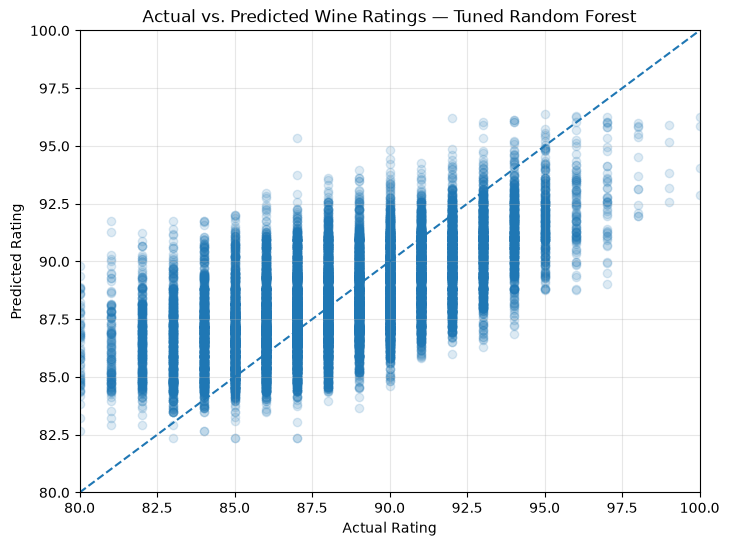

In [70]:
# Plot actual ratings against predicted ratings
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_multi,
    y_pred_best,
    alpha=0.15
)

# Add a reference line representing perfect predictions
plt.plot(
    [80, 100],
    [80, 100],
    linestyle="--"
)

plt.title("Actual vs. Predicted Wine Ratings — Tuned Random Forest")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.xlim(80, 100)
plt.ylim(80, 100)
plt.grid(True, alpha=0.3)

plt.show()

#### Interpretation of Actual vs. Predicted Ratings

The scatter plot shows a general positive relationship between actual and predicted wine ratings. However, predictions are concentrated around the middle of the rating range.

The model tends to overestimate some lower-rated wines and underestimate some of the highest-rated wines. This suggests that the Random Forest captures general rating patterns but struggles to predict extreme ratings accurately.

These observations are consistent with the test-set R2 of 0.428, indicating that the model explains part of the variation in professional wine ratings but leaves substantial variation unexplained.

Overall, the Random Forest performs better than the Linear Regression models evaluated in this project, but its predictions should not be treated as exact ratings.

## Final Conclusions

### Relationship Between Price and Ratings

The exploratory analysis found a moderate positive Pearson correlation of 0.4162 between wine price and professional rating. Average ratings increased from 85.91 points for wines priced at $0–15 to 92.82 points for wines priced above $100.

These results suggest that more expensive wines tend to receive higher professional ratings in this dataset. However, price alone does not guarantee a higher rating, and professional ratings are used here as a proxy for perceived quality.

### Machine Learning Results

Among the models evaluated, Random Forest achieved the best test-set performance, with an MAE of 1.848, an RMSE of 2.339, and an R2 of 0.428.

Price accounted for approximately 86.8% of the model's total feature importance, while variety accounted for 7.9% and country for 5.3%. These importance scores describe how the fitted model uses its predictors; they do not establish causation.

Grid Search tested four hyperparameter configurations but did not improve upon the initial Random Forest settings.

### Limitations and Future Work

The model explains only part of the variation in professional ratings. Other factors may contain useful predictive information, and the model tends to overestimate some lower ratings and underestimate some higher ratings.

Future work could explore additional non-text features, a broader hyperparameter search, more extensive cross-validation, and statistical testing of the price-rating relationship. Results should be interpreted as predictions of professional ratings rather than objective measurements of wine quality.